In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [2]:
from pathlib import Path

# Load the project dataset locally so the notebook can run without internet.
local_dataset = Path("../data/energydata_complete.csv")

if local_dataset.exists():
    df = pd.read_csv(local_dataset)
    print("Dataset loaded from project data folder.")
else:
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00374/energydata_complete.csv"
    df = pd.read_csv(url)
    print("Dataset loaded from UCI repository.")

print("Shape:", df.shape)
df.head()


Dataset loaded from project data folder.
Shape: (19735, 29)


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [3]:
print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  str    
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5           19735 non-null  float64
 12  RH_5         19735 non-null  float64
 13  T6           19735 non-null  float64
 14  RH_6         19735 non-null  float64
 15  T7           19735 non-null  float64
 16  RH_7         19735 non-null  float64
 17  T8           19735 non-null  float64
 18  RH_8         19735 non-null  float64

In [4]:
# Convert date column to datetime
df['date'] = pd.to_datetime(df['date'])

# Create useful time-based features
df['hour'] = df['date'].dt.hour
df['day'] = df['date'].dt.day
df['month'] = df['date'].dt.month
df['day_of_week'] = df['date'].dt.dayofweek
df['is_weekend'] = (df['day_of_week'] >= 5).astype(int)

print("Date features created successfully!")

print("\nNew columns:")
print(df[['date', 'hour', 'day', 'month', 'day_of_week', 'is_weekend']].head())

Date features created successfully!

New columns:
                 date  hour  day  month  day_of_week  is_weekend
0 2016-01-11 17:00:00    17   11      1            0           0
1 2016-01-11 17:10:00    17   11      1            0           0
2 2016-01-11 17:20:00    17   11      1            0           0
3 2016-01-11 17:30:00    17   11      1            0           0
4 2016-01-11 17:40:00    17   11      1            0           0


Electricity Consumption Statistics:
count    19735.000000
mean        97.694958
std        102.524891
min         10.000000
25%         50.000000
50%         60.000000
75%        100.000000
max       1080.000000
Name: Appliances, dtype: float64


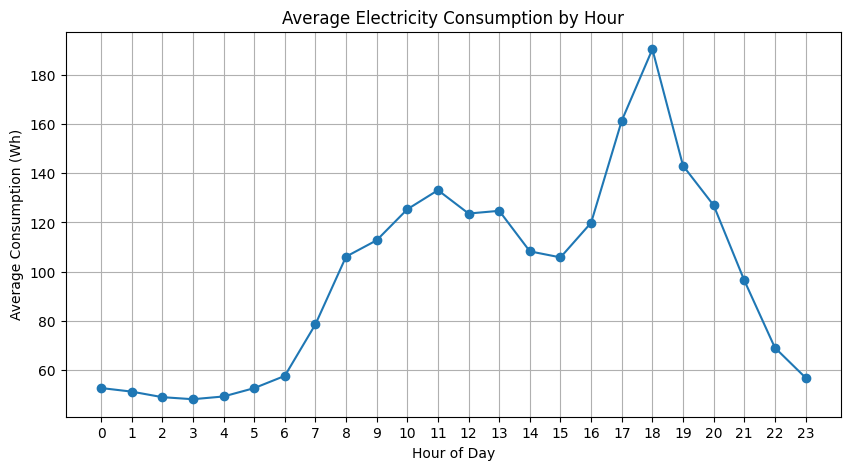

In [5]:
# Basic statistics of electricity consumption
print("Electricity Consumption Statistics:")
print(df['Appliances'].describe())

# Average consumption by hour
hourly_usage = df.groupby('hour')['Appliances'].mean()

plt.figure(figsize=(10, 5))
plt.plot(hourly_usage.index, hourly_usage.values, marker='o')
plt.title('Average Electricity Consumption by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Average Consumption (Wh)')
plt.xticks(range(24))
plt.grid(True)
plt.show()

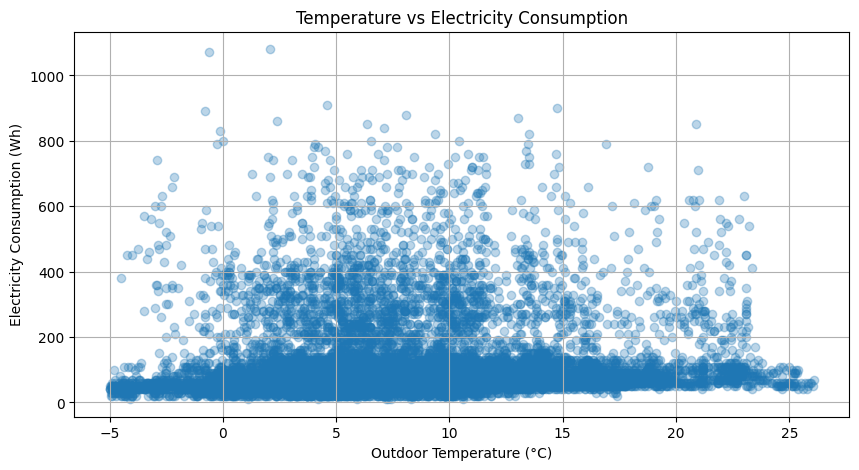

In [6]:
plt.figure(figsize=(10, 5))

plt.scatter(df['T_out'], df['Appliances'], alpha=0.3)

plt.title('Temperature vs Electricity Consumption')
plt.xlabel('Outdoor Temperature (°C)')
plt.ylabel('Electricity Consumption (Wh)')
plt.grid(True)

plt.show()

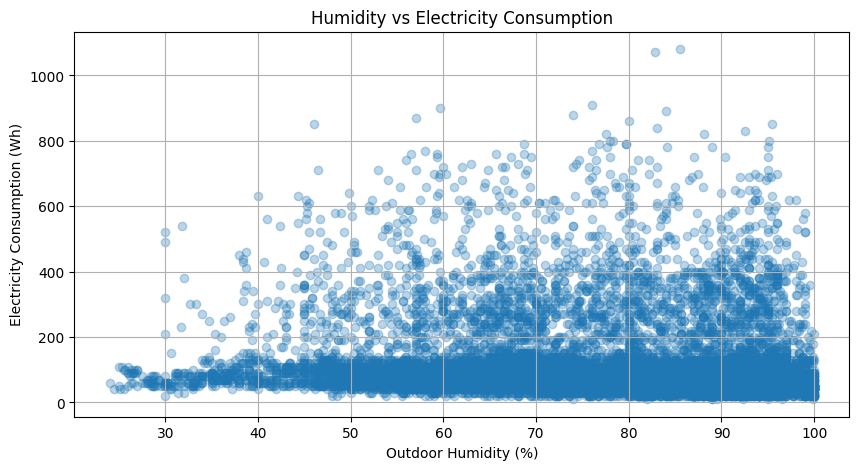

In [7]:
plt.figure(figsize=(10, 5))

plt.scatter(df['RH_out'], df['Appliances'], alpha=0.3)

plt.title('Humidity vs Electricity Consumption')
plt.xlabel('Outdoor Humidity (%)')
plt.ylabel('Electricity Consumption (Wh)')
plt.grid(True)

plt.show()

In [8]:
# Create a working copy of the dataset
df_model = df.copy()

# Sort data chronologically
df_model = df_model.sort_values("date").reset_index(drop=True)

# Previous electricity consumption
df_model["previous_consumption"] = df_model["Appliances"].shift(1)

# Remove first row because it has no previous consumption value
df_model = df_model.dropna().reset_index(drop=True)

print("Previous consumption feature added successfully!")
print(df_model[["date", "Appliances", "previous_consumption"]].head())

Previous consumption feature added successfully!
                 date  Appliances  previous_consumption
0 2016-01-11 17:10:00          60                  60.0
1 2016-01-11 17:20:00          50                  60.0
2 2016-01-11 17:30:00          50                  50.0
3 2016-01-11 17:40:00          60                  50.0
4 2016-01-11 17:50:00          50                  60.0


In [9]:
# ==========================================
# PREPARE FINAL FEATURES AND TARGET
# ==========================================

X_new = df_model.drop(columns=["Appliances", "date"])
y_new = df_model["Appliances"]

print("Features Shape:", X_new.shape)
print("Target Shape:", y_new.shape)

print("\nFeatures:")
print(X_new.columns.tolist())

Features Shape: (19734, 33)
Target Shape: (19734,)

Features:
['lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1', 'rv2', 'hour', 'day', 'month', 'day_of_week', 'is_weekend', 'previous_consumption']


In [10]:
# ==========================================
# FINAL TRAIN / TEST SPLIT
# ==========================================

# Keep the data in chronological order
split_index = int(len(X_new) * 0.80)

X_train_final = X_new.iloc[:split_index]
X_test_final = X_new.iloc[split_index:]

y_train_final = y_new.iloc[:split_index]
y_test_final = y_new.iloc[split_index:]

print("Training Data:", X_train_final.shape)
print("Testing Data :", X_test_final.shape)

Training Data: (15787, 33)
Testing Data : (3947, 33)


In [11]:
# ==========================================
# FINAL MODEL TRAINING
# ==========================================

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Create models
lr_final = LinearRegression()

dt_final = DecisionTreeRegressor(
    random_state=42
)

rf_final = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train models
lr_final.fit(X_train_final, y_train_final)
dt_final.fit(X_train_final, y_train_final)
rf_final.fit(X_train_final, y_train_final)

print("All final models trained successfully!")

All final models trained successfully!


### Evaluation protocol and interpretation

The dataset is kept in chronological order and split into the first 80% for training and the final 20% for testing. 
All four models are evaluated on the same held-out period. The Dummy Regressor is a reference baseline, not a competing ML algorithm. 
Negative R² values indicate performance worse than a mean-prediction reference on the test data.


In [12]:
# ==========================================
# FINAL MODEL EVALUATION (FOUR MODELS)
# ==========================================

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
import numpy as np

# Predictions from the three trained ML models
pred_lr_final = lr_final.predict(X_test_final)
pred_dt_final = dt_final.predict(X_test_final)
pred_rf_final = rf_final.predict(X_test_final)

# Baseline: predict the mean of the training target for every test row.
dummy_final = DummyRegressor(strategy="mean")
dummy_final.fit(X_train_final, y_train_final)
pred_dummy_final = dummy_final.predict(X_test_final)

def evaluate_model(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)
    print(f"\\n{name}")
    print(f"MAE  : {mae:.4f} Wh")
    print(f"RMSE : {rmse:.4f} Wh")
    print(f"R²   : {r2:.4f}")
    return mae, rmse, r2

lr_final_scores = evaluate_model("Linear Regression", y_test_final, pred_lr_final)
dt_final_scores = evaluate_model("Decision Tree", y_test_final, pred_dt_final)
rf_final_scores = evaluate_model("Random Forest", y_test_final, pred_rf_final)
dummy_final_scores = evaluate_model("Dummy Baseline", y_test_final, pred_dummy_final)

print("\\nInterpretation:")
print("A higher R² and lower MAE/RMSE indicate better test-set performance.")
print("A negative R² means the model performs worse than predicting the test-set mean.")


\nLinear Regression
MAE  : 28.2647 Wh
RMSE : 62.0270 Wh
R²   : 0.5358
\nDecision Tree
MAE  : 116.8077 Wh
RMSE : 200.5192 Wh
R²   : -3.8513
\nRandom Forest
MAE  : 88.2370 Wh
RMSE : 122.5808 Wh
R²   : -0.8130
\nDummy Baseline
MAE  : 52.6861 Wh
RMSE : 91.0535 Wh
R²   : -0.0003
\nInterpretation:
A higher R² and lower MAE/RMSE indicate better test-set performance.
A negative R² means the model performs worse than predicting the test-set mean.


In [13]:
# ==========================================
# MODEL PERFORMANCE COMPARISON
# ==========================================

final_results = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree", "Random Forest", "Dummy Baseline"],
    "MAE (Wh)": [lr_final_scores[0], dt_final_scores[0], rf_final_scores[0], dummy_final_scores[0]],
    "RMSE (Wh)": [lr_final_scores[1], dt_final_scores[1], rf_final_scores[1], dummy_final_scores[1]],
    "R² Score": [lr_final_scores[2], dt_final_scores[2], rf_final_scores[2], dummy_final_scores[2]]
})

display(final_results.style.format({
    "MAE (Wh)": "{:.4f}",
    "RMSE (Wh)": "{:.4f}",
    "R² Score": "{:.4f}"
}))

best_model_name = final_results.sort_values("R² Score", ascending=False).iloc[0]["Model"]
print(f"Best model on this chronological test set: {best_model_name}")


,Model,MAE (Wh),RMSE (Wh),R² Score
0,Linear Regression,28.2647,62.0270,0.5358
1,Decision Tree,116.8077,200.5192,-3.8513
2,Random Forest,88.2370,122.5808,-0.8130
3,Dummy Baseline,52.6861,91.0535,-0.0003


Best model on this chronological test set: Linear Regression


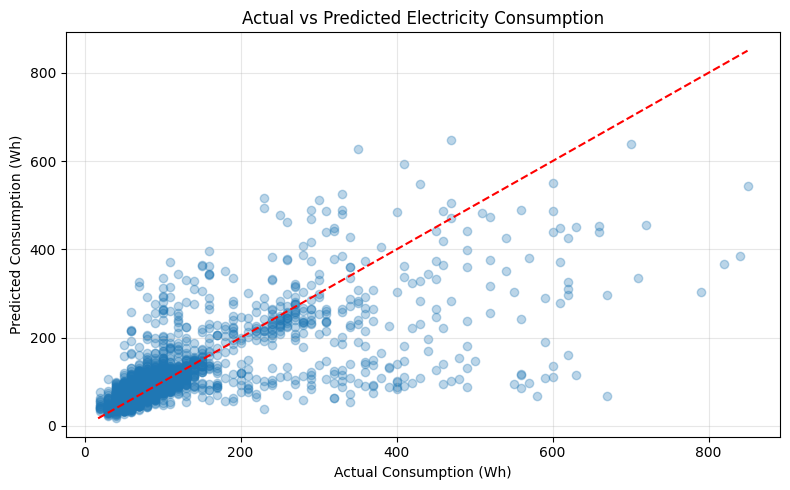

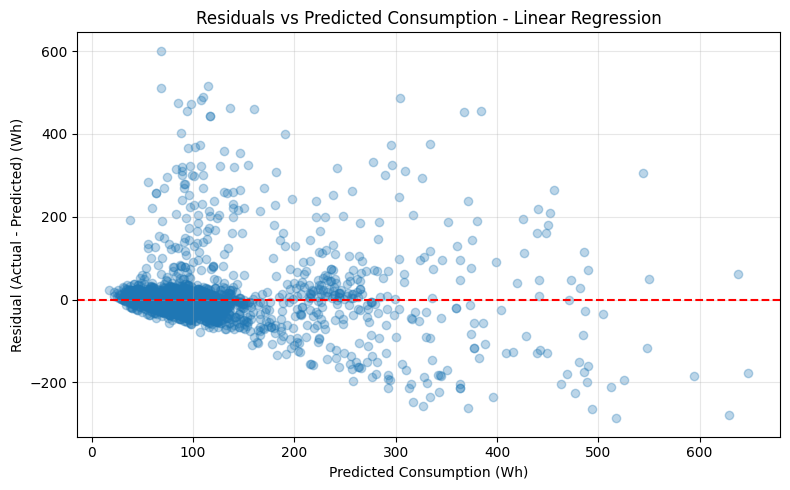

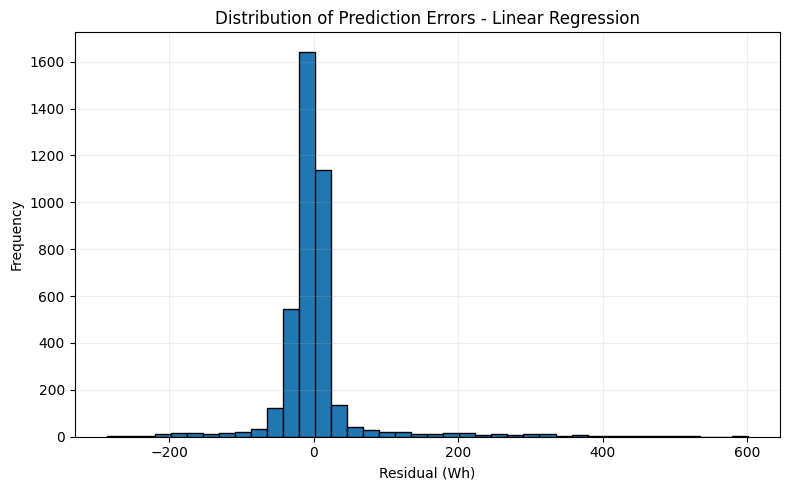

Mean residual: 1.2334 Wh
Residual standard deviation: 62.0147 Wh
MAE: 28.2647 Wh
RMSE: 62.027 Wh
TOP 10 IMPORTANT FEATURES (Random Forest)


,Importance
previous_consumption,0.604008
T3,0.019489
RH_1,0.018084
Press_mm_hg,0.017387
RH_3,0.016560
T4,0.016559
RH_5,0.016033
RH_2,0.015657
T8,0.014863
hour,0.014475


\nHIGH CONSUMPTION ANALYSIS
High Consumption Threshold: 330.0 Wh
High-Consumption Records: 1001
\nExample Predicted Electricity Consumption: 237.87 Wh
\nPREDICTION INPUT LIMITATION
The interactive app accepts a small set of user inputs.
Other model features are filled using training-set median values.
Therefore, the output is an estimate under partially specified conditions,
not a fully observed real-time household energy measurement.


In [14]:
# ==========================================
# FINAL PROJECT ANALYSIS
# ==========================================

# 1. Actual vs Predicted for the selected Linear Regression model
final_predictions = pred_lr_final

plt.figure(figsize=(8, 5))
plt.scatter(y_test_final, final_predictions, alpha=0.30)
line_min = min(y_test_final.min(), final_predictions.min())
line_max = max(y_test_final.max(), final_predictions.max())
plt.plot([line_min, line_max], [line_min, line_max], linestyle="--", color="red")
plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Actual Consumption (Wh)")
plt.ylabel("Predicted Consumption (Wh)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Prediction error / residual analysis
residuals = y_test_final.to_numpy() - final_predictions

plt.figure(figsize=(8, 5))
plt.scatter(final_predictions, residuals, alpha=0.30)
plt.axhline(0, linestyle="--", color="red")
plt.title("Residuals vs Predicted Consumption - Linear Regression")
plt.xlabel("Predicted Consumption (Wh)")
plt.ylabel("Residual (Actual - Predicted) (Wh)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=40, edgecolor="black")
plt.title("Distribution of Prediction Errors - Linear Regression")
plt.xlabel("Residual (Wh)")
plt.ylabel("Frequency")
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

print("Mean residual:", round(float(np.mean(residuals)), 4), "Wh")
print("Residual standard deviation:", round(float(np.std(residuals)), 4), "Wh")
print("MAE:", round(lr_final_scores[0], 4), "Wh")
print("RMSE:", round(lr_final_scores[1], 4), "Wh")

# 3. Feature Importance (Random Forest)
feature_importance = pd.Series(
    rf_final.feature_importances_,
    index=X_new.columns
).sort_values(ascending=False)

print("TOP 10 IMPORTANT FEATURES (Random Forest)")
display(feature_importance.head(10).to_frame("Importance"))

# 4. High Consumption Analysis
threshold = df_model["Appliances"].quantile(0.95)
high_usage = df_model[df_model["Appliances"] >= threshold]

print("\\nHIGH CONSUMPTION ANALYSIS")
print("High Consumption Threshold:", round(threshold, 2), "Wh")
print("High-Consumption Records:", len(high_usage))

# 5. Example prediction using a real held-out test row
sample_input = X_test_final.iloc[0:1]
sample_prediction = lr_final.predict(sample_input)[0]
print("\\nExample Predicted Electricity Consumption:", round(sample_prediction, 2), "Wh")

# 6. Explicit limitation of the interactive application
print("\\nPREDICTION INPUT LIMITATION")
print("The interactive app accepts a small set of user inputs.")
print("Other model features are filled using training-set median values.")
print("Therefore, the output is an estimate under partially specified conditions,")
print("not a fully observed real-time household energy measurement.")


In [15]:
# ==========================================
# USER INPUT BASED ELECTRICITY PREDICTION
# ==========================================

# These example values match the default values on the Streamlit Prediction page.
hour = 18
temperature = 20.0
humidity = 70.0
previous_consumption = 100.0
day_of_week = 0       # Monday
month = 3             # March
is_weekend = 0

# Use training-set median values as defaults for all other sensor features.
sample_input = X_train_final.median().to_frame().T

# Apply the same six user-selected conditions used by the app.
sample_input.loc[:, "hour"] = hour
sample_input.loc[:, "T_out"] = temperature
sample_input.loc[:, "RH_out"] = humidity
sample_input.loc[:, "previous_consumption"] = previous_consumption
sample_input.loc[:, "day_of_week"] = day_of_week
sample_input.loc[:, "month"] = month
sample_input.loc[:, "is_weekend"] = is_weekend

# Predict using the selected best model (Linear Regression on this test set).
user_prediction = lr_final.predict(sample_input[X_train_final.columns])[0]
user_prediction = max(0, user_prediction)

print("PREDICTED ELECTRICITY CONSUMPTION")
print(f"Estimated Consumption: {user_prediction:.2f} Wh")


PREDICTED ELECTRICITY CONSUMPTION
Estimated Consumption: 85.87 Wh
